In [ ]:
# ============================================================
# NOTEBOOK 4: EMBEDDING GENERATION
# ============================================================
# Project:
# Healthcare Retrieval-Augmented Generation (RAG) System
#
# Purpose:
# Convert the same NHS document chunks into dense vector
# embeddings using four different sentence embedding models.
#
# Models:
#   1. all-MiniLM-L6-v2
#   2. all-mpnet-base-v2
#   3. multilingual-e5-base
#   4. BGE-small-en-v1.5
#
# The same chunks and preprocessing pipeline are used for every
# model to maintain a fair experimental comparison.
# ============================================================


# ============================================================
# STEP 1: MOUNT GOOGLE DRIVE
# ============================================================
# Our NHS data and project files are stored in Google Drive.
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ============================================================
# STEP 2: INSTALL REQUIRED LIBRARIES
# ============================================================
# sentence-transformers:
#   Provides the framework for loading and using the four
#   selected sentence embedding models.
#
# These models will convert each NHS document chunk into a
# numerical vector representation.
# ============================================================

!pip install -q sentence-transformers

In [ ]:
# ============================================================
# STEP 3: IMPORT REQUIRED LIBRARIES
# ============================================================
# Path:
#   Used for managing project folders and file paths.
#
# JSON:
#   Used to read the chunk files created in Notebook 3 and
#   later store the generated embeddings.
#
# NumPy:
#   Used for numerical operations on embedding vectors.
#
# tqdm:
#   Displays progress bars while processing the NHS chunks.
#
# SentenceTransformer:
#   Loads and runs the four selected embedding models.
# ============================================================

from pathlib import Path
import json
import numpy as np

from tqdm import tqdm
from sentence_transformers import SentenceTransformer

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [ ]:
# ============================================================
# STEP 4: DEFINE PROJECT PATHS
# ============================================================
# This cell defines where the input chunks and generated
# embeddings will be stored.
#
# Input:
#   data/chunks/
#       Contains the 3,796 chunks generated in Notebook 3.
#
# Output:
#   data/embeddings/
#       Will contain a separate embedding dataset for each
#       of the four models.
# ============================================================

# Main project directory
PROJECT_DIR = Path("/content/drive/MyDrive/Healthcare_RAG")

# Input directory containing the chunks from Notebook 3
CHUNK_DIR = PROJECT_DIR / "data" / "chunks"

# Output directory for generated embeddings
EMBEDDING_DIR = PROJECT_DIR / "data" / "embeddings"

# Create the embedding directory if it does not already exist
EMBEDDING_DIR.mkdir(parents=True, exist_ok=True)

# Display the paths so we can verify them
print("=" * 70)
print("PROJECT PATHS")
print("=" * 70)

print(f"Project Directory : {PROJECT_DIR}")
print(f"Chunk Directory   : {CHUNK_DIR}")
print(f"Embedding Folder  : {EMBEDDING_DIR}")

print("=" * 70)

PROJECT PATHS
Project Directory : /content/drive/MyDrive/Healthcare_RAG
Chunk Directory   : /content/drive/MyDrive/Healthcare_RAG/data/chunks
Embedding Folder  : /content/drive/MyDrive/Healthcare_RAG/data/embeddings


In [ ]:
# ============================================================
# STEP 5: DEFINE THE FOUR EMBEDDING MODELS
# ============================================================
# These are the four embedding models specified in the
# dissertation methodology.
#
# The same NHS chunks will be passed through every model.
# This ensures a fair comparison because the embedding model
# is the main experimental variable.
#
# Models:
#   1. all-MiniLM-L6-v2
#   2. all-mpnet-base-v2
#   3. multilingual-e5-base
#   4. BGE-small-en-v1.5
# ============================================================

EMBEDDING_MODELS = {

    "MiniLM": "sentence-transformers/all-MiniLM-L6-v2",

    "MPNet": "sentence-transformers/all-mpnet-base-v2",

    "E5": "intfloat/multilingual-e5-base",

    "BGE": "BAAI/bge-small-en-v1.5"

}

# Display the models that will be used
print("=" * 70)
print("EMBEDDING MODELS SELECTED FOR THE EXPERIMENT")
print("=" * 70)

for model_name, model_id in EMBEDDING_MODELS.items():

    print(f"{model_name:10} : {model_id}")

print("=" * 70)

EMBEDDING MODELS SELECTED FOR THE EXPERIMENT
MiniLM     : sentence-transformers/all-MiniLM-L6-v2
MPNet      : sentence-transformers/all-mpnet-base-v2
E5         : intfloat/multilingual-e5-base
BGE        : BAAI/bge-small-en-v1.5


In [ ]:
# ============================================================
# STEP 6: LOAD ALL NHS DOCUMENT CHUNKS
# ============================================================
# The chunks were created in Notebook 3.
#
# Every embedding model will receive exactly the same chunks.
# This ensures that differences in retrieval performance later
# can be attributed to the embedding model rather than to
# differences in the input data.
# ============================================================

# Find all JSON chunk files
chunk_files = sorted(CHUNK_DIR.glob("*.json"))

print("=" * 70)
print("LOADING NHS DOCUMENT CHUNKS")
print("=" * 70)

print(f"Chunk Files Found : {len(chunk_files)}")

# ------------------------------------------------------------
# Load every chunk into one list
# ------------------------------------------------------------

all_chunks = []

for file_path in tqdm(chunk_files, desc="Loading chunk files"):

    with open(file_path, "r", encoding="utf-8") as file:

        chunks = json.load(file)

    all_chunks.extend(chunks)

# ------------------------------------------------------------
# Display dataset information
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("CHUNKS LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Total Articles : {len(chunk_files)}")
print(f"Total Chunks   : {len(all_chunks)}")

# ------------------------------------------------------------
# Display one sample chunk
# ------------------------------------------------------------

sample_chunk = all_chunks[0]

print("\n")
print("SAMPLE CHUNK")
print("-" * 70)

print(f"Chunk ID     : {sample_chunk['chunk_id']}")
print(f"Source File  : {sample_chunk['source_file']}")
print(f"Chunk Length : {sample_chunk['chunk_length']} characters")

print("\nText Preview:")
print(sample_chunk["text"][:500])

print("=" * 70)

LOADING NHS DOCUMENT CHUNKS
Chunk Files Found : 698


Loading chunk files: 100%|██████████| 698/698 [00:09<00:00, 71.63it/s] 



CHUNKS LOADED SUCCESSFULLY
Total Articles : 698
Total Chunks   : 3796


SAMPLE CHUNK
----------------------------------------------------------------------
Chunk ID     : 1
Source File  : aciclovir_zovirax.txt
Chunk Length : 456 characters

Text Preview:
# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.


In [ ]:
# ============================================================
# STEP 7: LOAD AND VERIFY THE FIRST EMBEDDING MODEL
# ============================================================
# We will process the four embedding models one at a time.
#
# Why?
#   - Reduces GPU/RAM usage.
#   - Prevents unnecessary memory problems in Google Colab.
#   - Allows us to record processing time for each model.
#
# The first model is:
#   all-MiniLM-L6-v2
# ============================================================

import time

# Select the first model
model_name = "MiniLM"
model_id = EMBEDDING_MODELS[model_name]

print("=" * 70)
print("LOADING EMBEDDING MODEL")
print("=" * 70)

print(f"Model Name : {model_name}")
print(f"Model ID   : {model_id}")

# Record model loading time
load_start_time = time.time()

embedding_model = SentenceTransformer(model_id)

load_time = time.time() - load_start_time

# Get embedding dimension
embedding_dimension = embedding_model.get_sentence_embedding_dimension()

print("\n")
print("=" * 70)
print("MODEL LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Model Name          : {model_name}")
print(f"Embedding Dimension : {embedding_dimension}")
print(f"Loading Time        : {load_time:.2f} seconds")

print("=" * 70)

LOADING EMBEDDING MODEL
Model Name : MiniLM
Model ID   : sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]



MODEL LOADED SUCCESSFULLY
Model Name          : MiniLM
Embedding Dimension : 384
Loading Time        : 4.40 seconds


/tmp/ipykernel_469/2433460651.py:36: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_dimension = embedding_model.get_sentence_embedding_dimension()


In [ ]:
# ============================================================
# STEP 8: GENERATE MINILM EMBEDDINGS
# ============================================================
# This cell:
#   1. Extracts the text from all 3,796 NHS chunks.
#   2. Generates a vector embedding for every chunk.
#   3. Normalizes the embeddings for cosine similarity.
#   4. Records the embedding generation time.
#   5. Stores the embeddings in memory.
#
# IMPORTANT:
#   The same chunks will later be passed to MPNet, E5, and BGE.
# ============================================================

# ------------------------------------------------------------
# Extract text from every chunk
# ------------------------------------------------------------

chunk_texts = [
    chunk["text"]
    for chunk in all_chunks
]

print("=" * 70)
print("GENERATING MINILM EMBEDDINGS")
print("=" * 70)

print(f"Model              : {model_name}")
print(f"Number of Chunks   : {len(chunk_texts)}")
print(f"Embedding Dimension: {embedding_dimension}")

# ------------------------------------------------------------
# Start timing
# ------------------------------------------------------------

generation_start_time = time.time()

# ------------------------------------------------------------
# Generate embeddings
#
# batch_size:
#   Controls how many chunks are processed at once.
#
# show_progress_bar:
#   Displays progress while embeddings are generated.
#
# normalize_embeddings:
#   Normalizes vectors so that inner-product similarity can
#   later be used as cosine similarity in FAISS.
# ------------------------------------------------------------

minilm_embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

# ------------------------------------------------------------
# Stop timing
# ------------------------------------------------------------

generation_time = time.time() - generation_start_time

# ------------------------------------------------------------
# Convert to NumPy float32
# ------------------------------------------------------------

minilm_embeddings = np.asarray(
    minilm_embeddings,
    dtype=np.float32
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("MINILM EMBEDDING GENERATION COMPLETED")
print("=" * 70)

print(f"Number of Embeddings : {len(minilm_embeddings)}")
print(f"Embedding Dimension  : {minilm_embeddings.shape[1]}")
print(f"Generation Time      : {generation_time:.2f} seconds")
print(f"Matrix Shape         : {minilm_embeddings.shape}")

print("=" * 70)

GENERATING MINILM EMBEDDINGS
Model              : MiniLM
Number of Chunks   : 3796
Embedding Dimension: 384


Batches:   0%|          | 0/119 [00:00<?, ?it/s]



MINILM EMBEDDING GENERATION COMPLETED
Number of Embeddings : 3796
Embedding Dimension  : 384
Generation Time      : 420.69 seconds
Matrix Shape         : (3796, 384)


In [ ]:
# ============================================================
# STEP 9: SAVE MINILM EMBEDDINGS WITH METADATA
# ============================================================
# This cell combines:
#   - Original NHS chunk metadata
#   - Original NHS text
#   - Generated MiniLM embedding
#
# The metadata is essential because later FAISS will return
# vector positions, and we need to trace those positions back
# to the original NHS article and chunk.
# ============================================================

# ------------------------------------------------------------
# Create output directory for MiniLM
# ------------------------------------------------------------

MINILM_DIR = EMBEDDING_DIR / "MiniLM"

MINILM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Create combined embedding records
# ------------------------------------------------------------

minilm_data = []

for chunk, embedding in zip(
    all_chunks,
    minilm_embeddings
):

    minilm_data.append({

        # Original chunk identifier
        "chunk_id": chunk["chunk_id"],

        # Original NHS source article
        "source_file": chunk["source_file"],

        # Original chunk length
        "chunk_length": chunk["chunk_length"],

        # Original NHS text
        "text": chunk["text"],

        # MiniLM vector
        "embedding": embedding.tolist()

    })

# ------------------------------------------------------------
# Save the embedding dataset
# ------------------------------------------------------------

minilm_output_file = MINILM_DIR / "all_embeddings.json"

with open(
    minilm_output_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        minilm_data,
        file,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("=" * 70)
print("MINILM EMBEDDINGS SAVED")
print("=" * 70)

print(f"Total Records : {len(minilm_data)}")
print(f"Embedding Size: {len(minilm_data[0]['embedding'])}")
print(f"Output File   : {minilm_output_file}")

print("=" * 70)

MINILM EMBEDDINGS SAVED
Total Records : 3796
Embedding Size: 384
Output File   : /content/drive/MyDrive/Healthcare_RAG/data/embeddings/MiniLM/all_embeddings.json


In [ ]:
# ============================================================
# STEP 10: VALIDATE MINILM EMBEDDINGS
# ============================================================
# This cell verifies that:
#   1. The saved file can be opened.
#   2. All 3,796 embeddings are present.
#   3. Each embedding has 384 dimensions.
#   4. The original NHS metadata is still attached.
# ============================================================

with open(
    minilm_output_file,
    "r",
    encoding="utf-8"
) as file:

    minilm_validation_data = json.load(file)


print("=" * 70)
print("MINILM EMBEDDING VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Basic dataset checks
# ------------------------------------------------------------

print(f"Total Records : {len(minilm_validation_data)}")

# First record
sample = minilm_validation_data[0]

print(f"Source File   : {sample['source_file']}")
print(f"Chunk ID      : {sample['chunk_id']}")
print(f"Chunk Length  : {sample['chunk_length']}")

print(f"Embedding Size: {len(sample['embedding'])}")

# ------------------------------------------------------------
# Verify every embedding has the expected dimension
# ------------------------------------------------------------

expected_dimension = embedding_dimension

invalid_embeddings = [
    item
    for item in minilm_validation_data
    if len(item["embedding"]) != expected_dimension
]

print(f"Invalid Embeddings : {len(invalid_embeddings)}")

# ------------------------------------------------------------
# Display text preview
# ------------------------------------------------------------

print("\nChunk Preview:")
print("-" * 70)
print(sample["text"][:500])

# ------------------------------------------------------------
# Final validation status
# ------------------------------------------------------------

if (
    len(minilm_validation_data) == len(all_chunks)
    and len(invalid_embeddings) == 0
):

    print("\n" + "=" * 70)
    print("VALIDATION PASSED")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("VALIDATION FAILED — CHECK THE DATA")
    print("=" * 70)

MINILM EMBEDDING VALIDATION
Total Records : 3796
Source File   : aciclovir_zovirax.txt
Chunk ID      : 1
Chunk Length  : 456
Embedding Size: 384
Invalid Embeddings : 0

Chunk Preview:
----------------------------------------------------------------------
# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.

VALIDATION PASSED


In [ ]:
# ============================================================
# STEP 11: LOAD MPNet EMBEDDING MODEL
# ============================================================
# Model:
#   all-mpnet-base-v2
#
# MPNet is the second embedding model specified in the
# dissertation methodology.
#
# We load it separately after MiniLM to avoid unnecessarily
# keeping multiple large models in GPU memory.
# ============================================================

# Model identification
model_name = "MPNet"
model_id = EMBEDDING_MODELS[model_name]

print("=" * 70)
print("LOADING MPNet EMBEDDING MODEL")
print("=" * 70)

print(f"Model Name : {model_name}")
print(f"Model ID   : {model_id}")

# ------------------------------------------------------------
# Record model loading time
# ------------------------------------------------------------

load_start_time = time.time()

embedding_model = SentenceTransformer(model_id)

load_time = time.time() - load_start_time

# ------------------------------------------------------------
# Get embedding dimension
# ------------------------------------------------------------

embedding_dimension = (
    embedding_model.get_sentence_embedding_dimension()
)

# ------------------------------------------------------------
# Display model information
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("MPNet MODEL LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Model Name          : {model_name}")
print(f"Embedding Dimension : {embedding_dimension}")
print(f"Loading Time        : {load_time:.2f} seconds")

print("=" * 70)

LOADING MPNet EMBEDDING MODEL
Model Name : MPNet
Model ID   : sentence-transformers/all-mpnet-base-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]



MPNet MODEL LOADED SUCCESSFULLY
Model Name          : MPNet
Embedding Dimension : 768
Loading Time        : 6.58 seconds


/tmp/ipykernel_469/2641941852.py:40: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension()


In [ ]:
# ============================================================
# STEP 12: GENERATE MPNet EMBEDDINGS
# ============================================================
# This cell:
#   1. Uses the same NHS chunks used for MiniLM.
#   2. Generates MPNet embeddings for all chunks.
#   3. Normalizes the embeddings for cosine similarity.
#   4. Measures the embedding generation time.
#   5. Stores the resulting vectors in memory.
#
# This keeps the experimental conditions identical across
# embedding models.
# ============================================================

print("=" * 70)
print("GENERATING MPNet EMBEDDINGS")
print("=" * 70)

print(f"Model              : {model_name}")
print(f"Number of Chunks   : {len(chunk_texts)}")
print(f"Embedding Dimension: {embedding_dimension}")

# ------------------------------------------------------------
# Start timing the embedding generation process
# ------------------------------------------------------------

generation_start_time = time.time()

# ------------------------------------------------------------
# Generate embeddings
# ------------------------------------------------------------

mpnet_embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

# ------------------------------------------------------------
# Calculate generation time
# ------------------------------------------------------------

generation_time = time.time() - generation_start_time

# ------------------------------------------------------------
# Convert embeddings to NumPy float32
# ------------------------------------------------------------

mpnet_embeddings = np.asarray(
    mpnet_embeddings,
    dtype=np.float32
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("MPNet EMBEDDING GENERATION COMPLETED")
print("=" * 70)

print(f"Number of Embeddings : {len(mpnet_embeddings)}")
print(f"Embedding Dimension  : {mpnet_embeddings.shape[1]}")
print(f"Generation Time      : {generation_time:.2f} seconds")
print(f"Matrix Shape         : {mpnet_embeddings.shape}")

print("=" * 70)

GENERATING MPNet EMBEDDINGS
Model              : MPNet
Number of Chunks   : 3796
Embedding Dimension: 768


Batches:   0%|          | 0/238 [00:00<?, ?it/s]



MPNet EMBEDDING GENERATION COMPLETED
Number of Embeddings : 3796
Embedding Dimension  : 768
Generation Time      : 2813.16 seconds
Matrix Shape         : (3796, 768)


In [ ]:
# ============================================================
# STEP 13: SAVE MPNet EMBEDDINGS WITH METADATA
# ============================================================
# This cell combines:
#   - Original NHS chunk metadata
#   - Original NHS text
#   - MPNet embedding vector
#
# Keeping the metadata with every vector allows us to later
# trace a FAISS result back to its original NHS article and
# document chunk.
# ============================================================

# ------------------------------------------------------------
# Create MPNet output directory
# ------------------------------------------------------------

MPNET_DIR = EMBEDDING_DIR / "MPNet"

MPNET_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Create records containing metadata + embedding
# ------------------------------------------------------------

mpnet_data = []

for chunk, embedding in zip(
    all_chunks,
    mpnet_embeddings
):

    mpnet_data.append({

        # Original chunk identifier
        "chunk_id": chunk["chunk_id"],

        # Original NHS source article
        "source_file": chunk["source_file"],

        # Original chunk length
        "chunk_length": chunk["chunk_length"],

        # Original NHS text
        "text": chunk["text"],

        # MPNet embedding vector
        "embedding": embedding.tolist()

    })

# ------------------------------------------------------------
# Define output file
# ------------------------------------------------------------

mpnet_output_file = MPNET_DIR / "all_embeddings.json"

# ------------------------------------------------------------
# Save embeddings and metadata
# ------------------------------------------------------------

with open(
    mpnet_output_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        mpnet_data,
        file,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("=" * 70)
print("MPNet EMBEDDINGS SAVED")
print("=" * 70)

print(f"Total Records : {len(mpnet_data)}")
print(f"Embedding Size: {len(mpnet_data[0]['embedding'])}")
print(f"Output File   : {mpnet_output_file}")

print("=" * 70)

MPNet EMBEDDINGS SAVED
Total Records : 3796
Embedding Size: 768
Output File   : /content/drive/MyDrive/Healthcare_RAG/data/embeddings/MPNet/all_embeddings.json


In [ ]:
# ============================================================
# STEP 14: VALIDATE MPNet EMBEDDINGS
# ============================================================
# This cell verifies:
#   1. The saved MPNet file can be opened.
#   2. All 3,796 embeddings are present.
#   3. Every embedding has 768 dimensions.
#   4. The original NHS metadata is preserved.
# ============================================================

with open(
    mpnet_output_file,
    "r",
    encoding="utf-8"
) as file:

    mpnet_validation_data = json.load(file)


print("=" * 70)
print("MPNet EMBEDDING VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print(f"Total Records : {len(mpnet_validation_data)}")

# ------------------------------------------------------------
# Inspect the first record
# ------------------------------------------------------------

sample = mpnet_validation_data[0]

print(f"Source File   : {sample['source_file']}")
print(f"Chunk ID      : {sample['chunk_id']}")
print(f"Chunk Length  : {sample['chunk_length']}")

print(f"Embedding Size: {len(sample['embedding'])}")

# ------------------------------------------------------------
# Verify embedding dimensions
# ------------------------------------------------------------

expected_dimension = embedding_dimension

invalid_embeddings = [
    item
    for item in mpnet_validation_data
    if len(item["embedding"]) != expected_dimension
]

print(f"Invalid Embeddings : {len(invalid_embeddings)}")

# ------------------------------------------------------------
# Display NHS text preview
# ------------------------------------------------------------

print("\nChunk Preview:")
print("-" * 70)
print(sample["text"][:500])

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    len(mpnet_validation_data) == len(all_chunks)
    and len(invalid_embeddings) == 0
):

    print("\n" + "=" * 70)
    print("VALIDATION PASSED")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("VALIDATION FAILED — CHECK THE DATA")
    print("=" * 70)

MPNet EMBEDDING VALIDATION
Total Records : 3796
Source File   : aciclovir_zovirax.txt
Chunk ID      : 1
Chunk Length  : 456
Embedding Size: 768
Invalid Embeddings : 0

Chunk Preview:
----------------------------------------------------------------------
# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.

VALIDATION PASSED


In [ ]:
# ============================================================
# STEP 15: LOAD AND PREPARE E5 EMBEDDING MODEL
# ============================================================
# Model:
#   multilingual-e5-base
#
# E5 is designed specifically for information retrieval.
#
# For document embeddings, E5 uses the prefix:
#
#       "passage: "
#
# Later, when we embed a user's question, we will use:
#
#       "query: "
#
# Keeping these two representations separate is important
# for correct E5 retrieval behaviour.
# ============================================================

# Model identification
model_name = "E5"
model_id = EMBEDDING_MODELS[model_name]

print("=" * 70)
print("LOADING E5 EMBEDDING MODEL")
print("=" * 70)

print(f"Model Name : {model_name}")
print(f"Model ID   : {model_id}")

# ------------------------------------------------------------
# Record model loading time
# ------------------------------------------------------------

load_start_time = time.time()

embedding_model = SentenceTransformer(model_id)

load_time = time.time() - load_start_time

# ------------------------------------------------------------
# Get embedding dimension
# ------------------------------------------------------------

embedding_dimension = (
    embedding_model.get_sentence_embedding_dimension()
)

# ------------------------------------------------------------
# Display model information
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("E5 MODEL LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Model Name          : {model_name}")
print(f"Embedding Dimension : {embedding_dimension}")
print(f"Loading Time        : {load_time:.2f} seconds")

print("=" * 70)

LOADING E5 EMBEDDING MODEL
Model Name : E5
Model ID   : intfloat/multilingual-e5-base


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]



E5 MODEL LOADED SUCCESSFULLY
Model Name          : E5
Embedding Dimension : 768
Loading Time        : 30.10 seconds


/tmp/ipykernel_469/1104490319.py:47: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension()


In [ ]:
# ============================================================
# STEP 16: PREPARE E5 DOCUMENT TEXT
# ============================================================
# E5 is trained for information retrieval using different
# prefixes for documents and queries.
#
# For documents:
#       passage: <document text>
#
# For user questions later:
#       query: <user question>
#
# Here we are embedding NHS DOCUMENTS, so we use "passage:".
# ============================================================

# Add the E5 passage prefix to every NHS chunk
e5_passage_texts = [
    f"passage: {chunk['text']}"
    for chunk in all_chunks
]

print("=" * 70)
print("E5 DOCUMENT TEXT PREPARED")
print("=" * 70)

print(f"Total Passages : {len(e5_passage_texts)}")

print("\nSample E5 Passage:")
print("-" * 70)

print(e5_passage_texts[0][:500])

print("=" * 70)

E5 DOCUMENT TEXT PREPARED
Total Passages : 3796

Sample E5 Passage:
----------------------------------------------------------------------
passage: # Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.


In [ ]:
# ============================================================
# STEP 17: GENERATE E5 DOCUMENT EMBEDDINGS
# ============================================================
# This cell:
#   1. Uses the prepared E5 "passage:" representations.
#   2. Generates an embedding for each of the 3,796 NHS chunks.
#   3. Normalizes the vectors for cosine similarity.
#   4. Records the total generation time.
#   5. Converts the result to NumPy float32.
#
# IMPORTANT:
#   We will use "query:" instead of "passage:" later when
#   embedding a user's question.
# ============================================================

print("=" * 70)
print("GENERATING E5 EMBEDDINGS")
print("=" * 70)

print(f"Model              : {model_name}")
print(f"Number of Passages : {len(e5_passage_texts)}")
print(f"Embedding Dimension: {embedding_dimension}")

# ------------------------------------------------------------
# Start timing
# ------------------------------------------------------------

generation_start_time = time.time()

# ------------------------------------------------------------
# Generate E5 embeddings
# ------------------------------------------------------------

e5_embeddings = embedding_model.encode(
    e5_passage_texts,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

# ------------------------------------------------------------
# Calculate generation time
# ------------------------------------------------------------

generation_time = time.time() - generation_start_time

# ------------------------------------------------------------
# Convert to NumPy float32
# ------------------------------------------------------------

e5_embeddings = np.asarray(
    e5_embeddings,
    dtype=np.float32
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("E5 EMBEDDING GENERATION COMPLETED")
print("=" * 70)

print(f"Number of Embeddings : {len(e5_embeddings)}")
print(f"Embedding Dimension  : {e5_embeddings.shape[1]}")
print(f"Generation Time      : {generation_time:.2f} seconds")
print(f"Matrix Shape         : {e5_embeddings.shape}")

print("=" * 70)

GENERATING E5 EMBEDDINGS
Model              : E5
Number of Passages : 3796
Embedding Dimension: 768


Batches:   0%|          | 0/238 [00:00<?, ?it/s]



E5 EMBEDDING GENERATION COMPLETED
Number of Embeddings : 3796
Embedding Dimension  : 768
Generation Time      : 2852.27 seconds
Matrix Shape         : (3796, 768)


In [ ]:
# ============================================================
# STEP 18: SAVE E5 EMBEDDINGS WITH METADATA
# ============================================================
# This cell combines:
#   - Original NHS chunk metadata
#   - Original NHS text
#   - E5 embedding vector
#
# IMPORTANT:
# The "passage:" prefix was used only during embedding
# generation. The original NHS text is stored unchanged so
# that retrieval results can later be shown exactly as the
# source content.
# ============================================================

# ------------------------------------------------------------
# Create E5 output directory
# ------------------------------------------------------------

E5_DIR = EMBEDDING_DIR / "E5"

E5_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Create records containing metadata + embedding
# ------------------------------------------------------------

e5_data = []

for chunk, embedding in zip(
    all_chunks,
    e5_embeddings
):

    e5_data.append({

        # Original chunk identifier
        "chunk_id": chunk["chunk_id"],

        # Original NHS source article
        "source_file": chunk["source_file"],

        # Original chunk length
        "chunk_length": chunk["chunk_length"],

        # Original NHS text
        "text": chunk["text"],

        # E5 embedding vector
        "embedding": embedding.tolist()

    })

# ------------------------------------------------------------
# Define output file
# ------------------------------------------------------------

e5_output_file = E5_DIR / "all_embeddings.json"

# ------------------------------------------------------------
# Save embeddings and metadata
# ------------------------------------------------------------

with open(
    e5_output_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        e5_data,
        file,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("=" * 70)
print("E5 EMBEDDINGS SAVED")
print("=" * 70)

print(f"Total Records : {len(e5_data)}")
print(f"Embedding Size: {len(e5_data[0]['embedding'])}")
print(f"Output File   : {e5_output_file}")

print("=" * 70)

E5 EMBEDDINGS SAVED
Total Records : 3796
Embedding Size: 768
Output File   : /content/drive/MyDrive/Healthcare_RAG/data/embeddings/E5/all_embeddings.json


In [ ]:
# ============================================================
# STEP 19: VALIDATE E5 EMBEDDINGS
# ============================================================
# This cell verifies:
#   1. The E5 embedding file can be opened.
#   2. All 3,796 embeddings are present.
#   3. Every embedding has 768 dimensions.
#   4. The original NHS metadata is preserved.
#   5. The original NHS text is unchanged.
# ============================================================

with open(
    e5_output_file,
    "r",
    encoding="utf-8"
) as file:

    e5_validation_data = json.load(file)


print("=" * 70)
print("E5 EMBEDDING VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print(f"Total Records : {len(e5_validation_data)}")

# ------------------------------------------------------------
# Inspect the first record
# ------------------------------------------------------------

sample = e5_validation_data[0]

print(f"Source File   : {sample['source_file']}")
print(f"Chunk ID      : {sample['chunk_id']}")
print(f"Chunk Length  : {sample['chunk_length']}")

print(f"Embedding Size: {len(sample['embedding'])}")

# ------------------------------------------------------------
# Verify embedding dimensions
# ------------------------------------------------------------

expected_dimension = embedding_dimension

invalid_embeddings = [
    item
    for item in e5_validation_data
    if len(item["embedding"]) != expected_dimension
]

print(f"Invalid Embeddings : {len(invalid_embeddings)}")

# ------------------------------------------------------------
# Display original NHS text
# ------------------------------------------------------------

print("\nOriginal NHS Chunk Preview:")
print("-" * 70)
print(sample["text"][:500])

# ------------------------------------------------------------
# Confirm that the stored text does NOT contain the E5
# "passage:" prefix.
# ------------------------------------------------------------

if sample["text"].startswith("passage:"):

    print("\nWARNING: Stored text contains the E5 passage prefix.")

else:

    print("\nStored text correctly preserved without the E5 prefix.")

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    len(e5_validation_data) == len(all_chunks)
    and len(invalid_embeddings) == 0
    and not sample["text"].startswith("passage:")
):

    print("\n" + "=" * 70)
    print("E5 VALIDATION PASSED")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("E5 VALIDATION FAILED — CHECK THE DATA")
    print("=" * 70)

E5 EMBEDDING VALIDATION
Total Records : 3796
Source File   : aciclovir_zovirax.txt
Chunk ID      : 1
Chunk Length  : 456
Embedding Size: 768
Invalid Embeddings : 0

Original NHS Chunk Preview:
----------------------------------------------------------------------
# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.

Stored text correctly preserved without the E5 prefix.

E5 VALIDATION PASSED


In [ ]:
# ============================================================
# STEP 20: LOAD BGE EMBEDDING MODEL
# ============================================================
# Model:
#   BAAI/bge-small-en-v1.5
#
# BGE is the fourth embedding model specified in the
# dissertation methodology.
#
# We use the same 3,796 NHS chunks that were used for:
#   - MiniLM
#   - MPNet
#   - E5
#
# This keeps the comparison fair.
# ============================================================

# Model identification
model_name = "BGE"
model_id = EMBEDDING_MODELS[model_name]

print("=" * 70)
print("LOADING BGE EMBEDDING MODEL")
print("=" * 70)

print(f"Model Name : {model_name}")
print(f"Model ID   : {model_id}")

# ------------------------------------------------------------
# Record model loading time
# ------------------------------------------------------------

load_start_time = time.time()

embedding_model = SentenceTransformer(model_id)

load_time = time.time() - load_start_time

# ------------------------------------------------------------
# Get embedding dimension
# ------------------------------------------------------------

embedding_dimension = (
    embedding_model.get_sentence_embedding_dimension()
)

# ------------------------------------------------------------
# Display model information
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("BGE MODEL LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Model Name          : {model_name}")
print(f"Embedding Dimension : {embedding_dimension}")
print(f"Loading Time        : {load_time:.2f} seconds")

print("=" * 70)

LOADING BGE EMBEDDING MODEL
Model Name : BGE
Model ID   : BAAI/bge-small-en-v1.5


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]



BGE MODEL LOADED SUCCESSFULLY
Model Name          : BGE
Embedding Dimension : 384
Loading Time        : 3.53 seconds


/tmp/ipykernel_469/4282436411.py:44: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension()


In [ ]:
# ============================================================
# STEP 21: GENERATE BGE EMBEDDINGS
# ============================================================
# This cell:
#   1. Uses the same 3,796 NHS document chunks.
#   2. Generates BGE embeddings for every chunk.
#   3. Normalizes the vectors for cosine similarity.
#   4. Measures the embedding generation time.
#   5. Converts the result to NumPy float32.
#
# This is the fourth and final embedding model.
# ============================================================

print("=" * 70)
print("GENERATING BGE EMBEDDINGS")
print("=" * 70)

print(f"Model              : {model_name}")
print(f"Number of Chunks   : {len(chunk_texts)}")
print(f"Embedding Dimension: {embedding_dimension}")

# ------------------------------------------------------------
# Start timing
# ------------------------------------------------------------

generation_start_time = time.time()

# ------------------------------------------------------------
# Generate BGE embeddings
# ------------------------------------------------------------

bge_embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

# ------------------------------------------------------------
# Calculate generation time
# ------------------------------------------------------------

generation_time = time.time() - generation_start_time

# ------------------------------------------------------------
# Convert embeddings to NumPy float32
# ------------------------------------------------------------

bge_embeddings = np.asarray(
    bge_embeddings,
    dtype=np.float32
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("BGE EMBEDDING GENERATION COMPLETED")
print("=" * 70)

print(f"Number of Embeddings : {len(bge_embeddings)}")
print(f"Embedding Dimension  : {bge_embeddings.shape[1]}")
print(f"Generation Time      : {generation_time:.2f} seconds")
print(f"Matrix Shape         : {bge_embeddings.shape}")

print("=" * 70)

GENERATING BGE EMBEDDINGS
Model              : BGE
Number of Chunks   : 3796
Embedding Dimension: 384


Batches:   0%|          | 0/119 [00:00<?, ?it/s]



BGE EMBEDDING GENERATION COMPLETED
Number of Embeddings : 3796
Embedding Dimension  : 384
Generation Time      : 934.92 seconds
Matrix Shape         : (3796, 384)


In [ ]:
# ============================================================
# STEP 22: SAVE BGE EMBEDDINGS WITH METADATA
# ============================================================
# This cell combines:
#   - Original NHS chunk metadata
#   - Original NHS text
#   - BGE embedding vector
#
# The original NHS text is stored unchanged so that the
# retrieved content can later be displayed as evidence/source
# material in the RAG chatbot.
# ============================================================

# ------------------------------------------------------------
# Create BGE output directory
# ------------------------------------------------------------

BGE_DIR = EMBEDDING_DIR / "BGE"

BGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Create records containing metadata + embedding
# ------------------------------------------------------------

bge_data = []

for chunk, embedding in zip(
    all_chunks,
    bge_embeddings
):

    bge_data.append({

        # Original chunk identifier
        "chunk_id": chunk["chunk_id"],

        # Original NHS source article
        "source_file": chunk["source_file"],

        # Original chunk length
        "chunk_length": chunk["chunk_length"],

        # Original NHS text
        "text": chunk["text"],

        # BGE embedding vector
        "embedding": embedding.tolist()

    })

# ------------------------------------------------------------
# Define output file
# ------------------------------------------------------------

bge_output_file = BGE_DIR / "all_embeddings.json"

# ------------------------------------------------------------
# Save embeddings and metadata
# ------------------------------------------------------------

with open(
    bge_output_file,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        bge_data,
        file,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("=" * 70)
print("BGE EMBEDDINGS SAVED")
print("=" * 70)

print(f"Total Records : {len(bge_data)}")
print(f"Embedding Size: {len(bge_data[0]['embedding'])}")
print(f"Output File   : {bge_output_file}")

print("=" * 70)

BGE EMBEDDINGS SAVED
Total Records : 3796
Embedding Size: 384
Output File   : /content/drive/MyDrive/Healthcare_RAG/data/embeddings/BGE/all_embeddings.json


In [ ]:
# ============================================================
# STEP 23: VALIDATE BGE EMBEDDINGS
# ============================================================
# This cell verifies:
#   1. The BGE embedding file can be opened.
#   2. All 3,796 embeddings are present.
#   3. Every embedding has the expected dimension.
#   4. The original NHS metadata is preserved.
#   5. The original NHS text is preserved.
# ============================================================

with open(
    bge_output_file,
    "r",
    encoding="utf-8"
) as file:

    bge_validation_data = json.load(file)


print("=" * 70)
print("BGE EMBEDDING VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Basic dataset information
# ------------------------------------------------------------

print(f"Total Records : {len(bge_validation_data)}")

# ------------------------------------------------------------
# Inspect the first record
# ------------------------------------------------------------

sample = bge_validation_data[0]

print(f"Source File   : {sample['source_file']}")
print(f"Chunk ID      : {sample['chunk_id']}")
print(f"Chunk Length  : {sample['chunk_length']}")

print(f"Embedding Size: {len(sample['embedding'])}")

# ------------------------------------------------------------
# Verify embedding dimensions
# ------------------------------------------------------------

expected_dimension = embedding_dimension

invalid_embeddings = [
    item
    for item in bge_validation_data
    if len(item["embedding"]) != expected_dimension
]

print(f"Invalid Embeddings : {len(invalid_embeddings)}")

# ------------------------------------------------------------
# Display original NHS text
# ------------------------------------------------------------

print("\nChunk Preview:")
print("-" * 70)
print(sample["text"][:500])

# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

if (
    len(bge_validation_data) == len(all_chunks)
    and len(invalid_embeddings) == 0
):

    print("\n" + "=" * 70)
    print("BGE VALIDATION PASSED")
    print("=" * 70)

else:

    print("\n" + "=" * 70)
    print("BGE VALIDATION FAILED — CHECK THE DATA")
    print("=" * 70)

BGE EMBEDDING VALIDATION
Total Records : 3796
Source File   : aciclovir_zovirax.txt
Chunk ID      : 1
Chunk Length  : 456
Embedding Size: 384
Invalid Embeddings : 0

Chunk Preview:
----------------------------------------------------------------------
# Aciclovir (Zovirax)

Aciclovir is an antiviral medicine used to treat certain infections. Most types are only available with a prescription, but you can buy some types from shops and pharmacies.

## What aciclovir is for

Aciclovir is used to treat infections such as:

• cold sores

• shingles

• chickenpox

• genital herpes

• herpes simplex eye infections

It's also sometimes used to prevent these infections in people with a weakened immune system.

BGE VALIDATION PASSED


In [ ]:
# ============================================================
# STEP 24: CREATE EMBEDDING MODEL EXPERIMENTAL SUMMARY
# ============================================================
# This cell creates a structured summary of the four embedding
# models used in the dissertation experiment.
#
# We record:
#   - Model name
#   - Hugging Face model ID
#   - Number of chunks embedded
#   - Embedding dimension
#
# The summary will later help us create:
#   - Dissertation tables
#   - Graphs
#   - Model comparison figures
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# Create model summary
# ------------------------------------------------------------

embedding_summary = pd.DataFrame({

    "Model": [
        "MiniLM",
        "MPNet",
        "E5",
        "BGE"
    ],

    "Model_ID": [
        EMBEDDING_MODELS["MiniLM"],
        EMBEDDING_MODELS["MPNet"],
        EMBEDDING_MODELS["E5"],
        EMBEDDING_MODELS["BGE"]
    ],

    "Number_of_Chunks": [
        len(minilm_data),
        len(mpnet_data),
        len(e5_data),
        len(bge_data)
    ],

    "Embedding_Dimension": [
        len(minilm_data[0]["embedding"]),
        len(mpnet_data[0]["embedding"]),
        len(e5_data[0]["embedding"]),
        len(bge_data[0]["embedding"])
    ]
})

# ------------------------------------------------------------
# Display the summary
# ------------------------------------------------------------

print("=" * 70)
print("EMBEDDING MODEL EXPERIMENTAL SUMMARY")
print("=" * 70)

display(embedding_summary)

print("=" * 70)

EMBEDDING MODEL EXPERIMENTAL SUMMARY


,Model,Model_ID,Number_of_Chunks,Embedding_Dimension
0,MiniLM,sentence-transformers/all-MiniLM-L6-v2,3796,384
1,MPNet,sentence-transformers/all-mpnet-base-v2,3796,768
2,E5,intfloat/multilingual-e5-base,3796,768
3,BGE,BAAI/bge-small-en-v1.5,3796,384


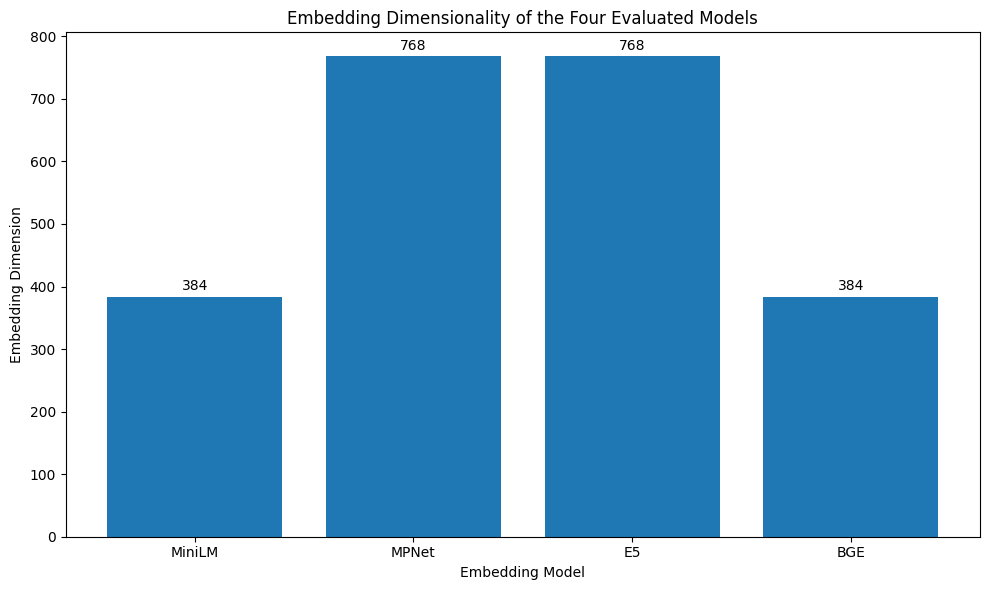

GRAPH SAVED SUCCESSFULLY
Saved To : /content/drive/MyDrive/Healthcare_RAG/data/embeddings/embedding_dimension_comparison.png


In [ ]:
# ============================================================
# STEP 25: CREATE EMBEDDING DIMENSION COMPARISON GRAPH
# ============================================================
# This cell creates a dissertation-ready figure showing the
# embedding dimensionality of the four models.
#
# The figure is based on the actual models used in the
# experiment — no manually entered results.
#
# Output:
#   data/embeddings/embedding_dimension_comparison.png
#
# This figure can later be used in the dissertation when
# describing the characteristics of the embedding models.
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Extract data from the experimental summary
# ------------------------------------------------------------

models = embedding_summary["Model"]

dimensions = embedding_summary["Embedding_Dimension"]

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    models,
    dimensions
)

# ------------------------------------------------------------
# Add labels and title
# ------------------------------------------------------------

plt.xlabel("Embedding Model")

plt.ylabel("Embedding Dimension")

plt.title(
    "Embedding Dimensionality of the Four Evaluated Models"
)

# ------------------------------------------------------------
# Display the exact value above each bar
# ------------------------------------------------------------

for i, value in enumerate(dimensions):

    plt.text(
        i,
        value + 10,
        str(value),
        ha="center"
    )

# ------------------------------------------------------------
# Improve layout
# ------------------------------------------------------------

plt.tight_layout()

# ------------------------------------------------------------
# Save the figure
# ------------------------------------------------------------

dimension_graph_path = (
    EMBEDDING_DIR /
    "embedding_dimension_comparison.png"
)

plt.savefig(
    dimension_graph_path,
    dpi=300,
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Display graph
# ------------------------------------------------------------

plt.show()

print("=" * 70)
print("GRAPH SAVED SUCCESSFULLY")
print("=" * 70)

print(f"Saved To : {dimension_graph_path}")

print("=" * 70)

In [ ]:
# ============================================================
# STEP 26: FINAL NOTEBOOK 4 VERIFICATION
# ============================================================
# This cell performs the final integrity check for the
# embedding-generation stage.
#
# We verify:
#   - All four embedding files exist.
#   - Each contains 3,796 records.
#   - Each model has the expected embedding dimension.
#
# Expected dimensions:
#   MiniLM : 384
#   MPNet  : 768
#   E5     : 768
#   BGE    : 384
#
# If all checks pass, Notebook 4 is complete.
# ============================================================

# Expected values based on the selected models
expected_chunks = 3796

expected_dimensions = {
    "MiniLM": 384,
    "MPNet": 768,
    "E5": 768,
    "BGE": 384
}

print("=" * 70)
print("FINAL NOTEBOOK 4 VERIFICATION")
print("=" * 70)

all_checks_passed = True

# ------------------------------------------------------------
# Check each embedding model
# ------------------------------------------------------------

for model_name, expected_dimension in expected_dimensions.items():

    embedding_file = (
        EMBEDDING_DIR /
        model_name /
        "all_embeddings.json"
    )

    print("\n" + "-" * 70)
    print(f"Checking: {model_name}")

    # Check whether file exists
    if not embedding_file.exists():

        print(" Embedding file NOT FOUND")
        all_checks_passed = False
        continue

    # Load embedding data
    with open(
        embedding_file,
        "r",
        encoding="utf-8"
    ) as file:

        data = json.load(file)

    actual_chunks = len(data)

    actual_dimension = len(
        data[0]["embedding"]
    )

    print(f"File Exists          : true")
    print(f"Number of Embeddings : {actual_chunks}")
    print(f"Expected Embeddings  : {expected_chunks}")
    print(f"Embedding Dimension  : {actual_dimension}")
    print(f"Expected Dimension   : {expected_dimension}")

    # --------------------------------------------------------
    # Validate number of embeddings
    # --------------------------------------------------------

    if actual_chunks != expected_chunks:

        print("❌ Chunk count mismatch")
        all_checks_passed = False

    else:

        print(" Chunk count correct")

    # --------------------------------------------------------
    # Validate embedding dimension
    # --------------------------------------------------------

    if actual_dimension != expected_dimension:

        print(" Embedding dimension mismatch")
        all_checks_passed = False

    else:

        print(" Embedding dimension correct")


# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

print("\n")
print("=" * 70)

if all_checks_passed:

    print(" NOTEBOOK 4 VERIFICATION PASSED")
    print("=" * 70)
    print("All four embedding datasets are ready for FAISS.")

else:

    print(" NOTEBOOK 4 VERIFICATION FAILED")
    print("=" * 70)
    print("Check the errors above before continuing.")

print("=" * 70)

FINAL NOTEBOOK 4 VERIFICATION

----------------------------------------------------------------------
Checking: MiniLM
File Exists          : true
Number of Embeddings : 3796
Expected Embeddings  : 3796
Embedding Dimension  : 384
Expected Dimension   : 384
 Chunk count correct
 Embedding dimension correct

----------------------------------------------------------------------
Checking: MPNet
File Exists          : true
Number of Embeddings : 3796
Expected Embeddings  : 3796
Embedding Dimension  : 768
Expected Dimension   : 768
 Chunk count correct
 Embedding dimension correct

----------------------------------------------------------------------
Checking: E5
File Exists          : true
Number of Embeddings : 3796
Expected Embeddings  : 3796
Embedding Dimension  : 768
Expected Dimension   : 768
 Chunk count correct
 Embedding dimension correct

----------------------------------------------------------------------
Checking: BGE
File Exists          : true
Number of Embeddings : 3796
Ex